In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import preprocessing, model_selection, metrics

# Carga de Dataframes modificados

In [2]:
df_labeled_all = pd.read_parquet('../Data_parcial2_mineria/df_labeled_all.parquet')
df_labeled = pd.read_parquet('../Data_parcial2_mineria/df_labeled.parquet')

df_unlabeled_all = pd.read_parquet('../Data_parcial2_mineria/df_unlabeled_all.parquet')
df_unlabeled = pd.read_parquet('../Data_parcial2_mineria/df_unlabeled.parquet')

In [3]:
df_unlabeled = df_unlabeled.rename(columns = {"Period_fit": "PPE"})
labels_classALeRCE = ['SNIa', 'SNIbc', 'SNII', 'SLSN','QSO','AGN', 'Blazar', 'YSO','CV/Nova',
                       'LPV', 'E', 'DSCT', 'RRL', 'CEP','Periodic-Other']
labels_classTop = ['Transient','Stochastic','Periodic']

# Definir Función para Graficar Matriz de Confusión e Importancia de Características

In [4]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusionMatrix(y_true, y_pred, labels, title, figsize = (10, 9)):
    
    print(classification_report(y_true, y_pred))
    
    print("Accuracy:", "%0.2f" % metrics.accuracy_score(y_true, y_pred))
    print("Balanced accuracy:","%0.2f" %  metrics.balanced_accuracy_score(y_true, y_pred))
    
    print("macro precision: ","%0.2f" %  metrics.precision_score(y_true, y_pred, average='macro'))
    print("macro recall: ","%0.2f" %  metrics.recall_score(y_true, y_pred, average='macro'))
    print("macro F1: ","%0.2f" %  metrics.f1_score(y_true, y_pred, average='macro'))
        
    cm = confusion_matrix(y_true, y_pred, normalize='true', labels = labels)*100
    
    # Renderizar la matriz visualmente
    fig, ax = plt.subplots(figsize=figsize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap='Blues', values_format='.0f', colorbar=True,
              xticks_rotation=45, ax=ax)
    disp.im_.set_clim(0, 100)   #definir los colores en el rango de 0 a 100
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

def plot_feature_importances(model, feature_names, title):
    I = np.argsort(model.feature_importances_)[::-1]
    I = I[0:60]
    for i in I[0:30]:
        print(feature_names[i], "& %.3f" % (model.feature_importances_[i]))
    fig, ax = plt.subplots(figsize=(16, 5), tight_layout=True)
    x_plot = np.arange(len(I))
    plt.xticks(x_plot, [feature_names[i] for i in I], rotation='vertical')
    ax.bar(x_plot, height=model.feature_importances_[I]);
    plt.title(title)
    plt.show()

# Influencia de la Magnitud en el modelo

Otra forma de analizar que tanto influye la magnitud de las fuetes en la clasificación que no se realizó en el artículo, es organizar los datos en orden de magnitud (en r en este caso). Realizar el entrenamiento con las fuentes más brillantes y probar con las menos brillantes.

Si la magnitud de los objetos (que se ve reflejada en las variables relacionadas con las bandas) realmente influye en el desempeño del modelo, la efectividad debería verse reducida considerablemente, basándonos en la premisa de que el modelo le da mayor importancia a las fuentes brillantes.

## Organizar datos

In [5]:
labeled_org = df_labeled.copy()
labeled_org['Mean_2'] = df_labeled_all['Mean_2']

(array([  615.,  6783., 11598., 16173., 20333., 18670., 16136., 10816.,
         2022.,   155.]),
 array([11.56309102, 12.58736146, 13.6116319 , 14.63590234, 15.66017278,
        16.68444323, 17.70871367, 18.73298411, 19.75725455, 20.78152499,
        21.80579544]),
 <BarContainer object of 10 artists>)

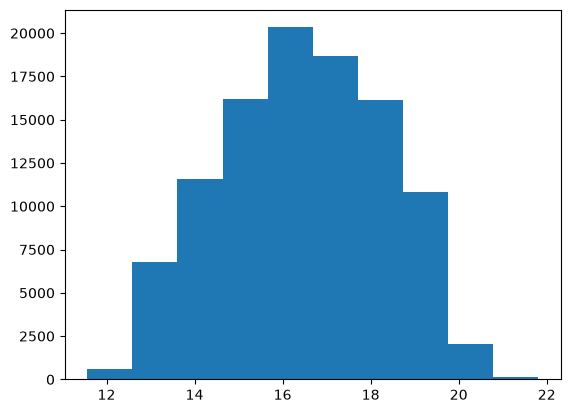

In [6]:
plt.hist(labeled_org['Mean_2'])

In [7]:
labeled_org = labeled_org.fillna(-999)

## Separar datos

In [8]:
labeled_org.shape

(123496, 156)

In [9]:
def split_por_magnitud(df, col_mag, col_clase, frac_train=0.8):
    tr, te = [], []
    for c, g in df.groupby(col_clase):
        g = g[g[col_mag] != -999].sort_values(col_mag)
        n = int(round(len(g) * frac_train))
        tr.append(g.iloc[:n]); te.append(g.iloc[n:])
    return pd.concat(tr), pd.concat(te)

train, test = split_por_magnitud(labeled_org, "Mean_2", "classALeRCE", 0.8)

In [10]:
X_tr = train.iloc[:, 1:153]
y_tr1 = train['classTop']
y_tr2 = train['classALeRCE']

X_ts = test.iloc[:, 1:153]
y_ts1 = test['classTop']
y_ts2 = test['classALeRCE']

In [11]:
#datos para los arboles del segundo nivel

X_tr_Stochastic = X_tr.loc[y_tr1 == 'Stochastic', :]
y_tr_Stochastic = y_tr2.loc[y_tr1 == 'Stochastic']

X_tr_Periodic = X_tr.loc[y_tr1 == 'Periodic', :]
y_tr_Periodic = y_tr2.loc[y_tr1 == 'Periodic']

X_tr_Transient = X_tr.loc[y_tr1 == 'Transient', :]
y_tr_Transient = y_tr2.loc[y_tr1 == 'Transient']

X_ts_Stochastic = X_ts
X_ts_Periodic = X_ts
X_ts_Transient = X_ts

print(f'Stochastic sub-classes: {y_tr_Stochastic.unique()} \n')
print(f'Periodic sub-classes: {y_tr_Periodic.unique()} \n')
print(f'Transient sub-classes: {y_tr_Transient.unique()} \n')

Stochastic sub-classes: <ArrowStringArray>
['AGN', 'Blazar', 'CV/Nova', 'QSO', 'YSO']
Length: 5, dtype: str 

Periodic sub-classes: <ArrowStringArray>
['CEP', 'DSCT', 'E', 'LPV', 'Periodic-Other', 'RRL']
Length: 6, dtype: str 

Transient sub-classes: <ArrowStringArray>
['SLSN', 'SNII', 'SNIa', 'SNIbc']
Length: 4, dtype: str 



## Distribución de datos

<BarContainer object of 3 artists>

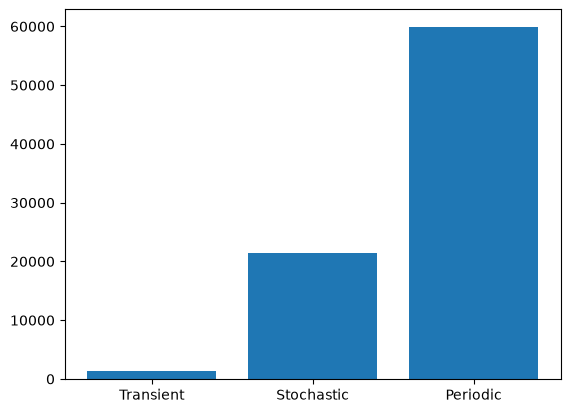

In [12]:
plt.bar(labels_classTop, [y_tr_Transient.count(), y_tr_Stochastic.count(), y_tr_Periodic.count()])

<Figure size 1000x600 with 0 Axes>

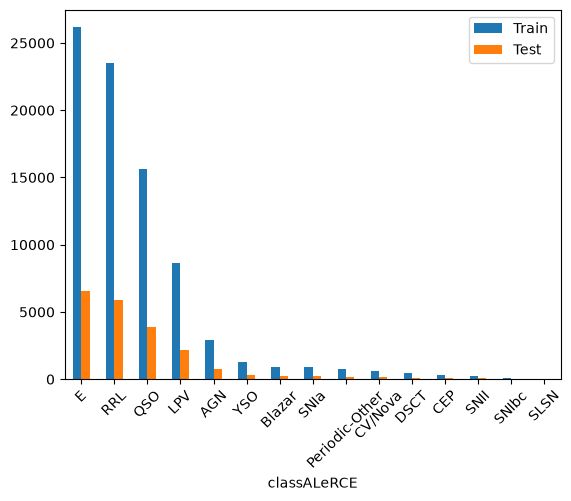

In [13]:
count = pd.DataFrame({'Train': y_tr2.value_counts(), 'Test': y_ts2.value_counts()})

plt.figure(figsize=(10,6))
count.plot(kind='bar')
plt.xticks(rotation=45)
plt.show()

## BRF de Dos Niveles

## BRF Primer Nivel

In [14]:
from imblearn.ensemble import BalancedRandomForestClassifier as RandomForestClassifier

# Estos hiperparámetros son extraidos directamente del código publicado en el artículo
BRF1 = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',   #en el artículo se coloca 'auto', pero son lo mismo segun la documentación de imblearn
            max_depth=None,
            n_jobs=-1,
            bootstrap=True,
            class_weight='balanced_subsample',
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1
    )

BRF1.fit(X_tr, y_tr1)

y_true, y_pred = y_ts1, BRF1.predict(X_ts)
y_pred_proba_BRF1 = BRF1.predict_proba(X_ts)

#organizar por probabilidad
classes_order_proba_BRF1 = BRF1.classes_
print(classes_order_proba_BRF1)

features = list(X_tr)

['Periodic' 'Stochastic' 'Transient']


### Matriz de Confusión

| Classifier | Precision | Recall | F1-score |
| :--- | :--- | :--- | :--- |
| BRF—top | $0.96 \pm 0.01$ | $0.99 \pm 0.01$ | $0.97 \pm 0.01$ |
| BRF—bottom | $0.57 \pm 0.01$ | $0.76 \pm 0.02$ | $0.59 \pm 0.01$ |

              precision    recall  f1-score   support

    Periodic       1.00      0.89      0.94     14978
  Stochastic       0.77      0.99      0.87      5361
   Transient       0.80      1.00      0.89       322

    accuracy                           0.92     20661
   macro avg       0.86      0.96      0.90     20661
weighted avg       0.94      0.92      0.92     20661

Accuracy: 0.92
Balanced accuracy: 0.96
macro precision:  0.86
macro recall:  0.96
macro F1:  0.90


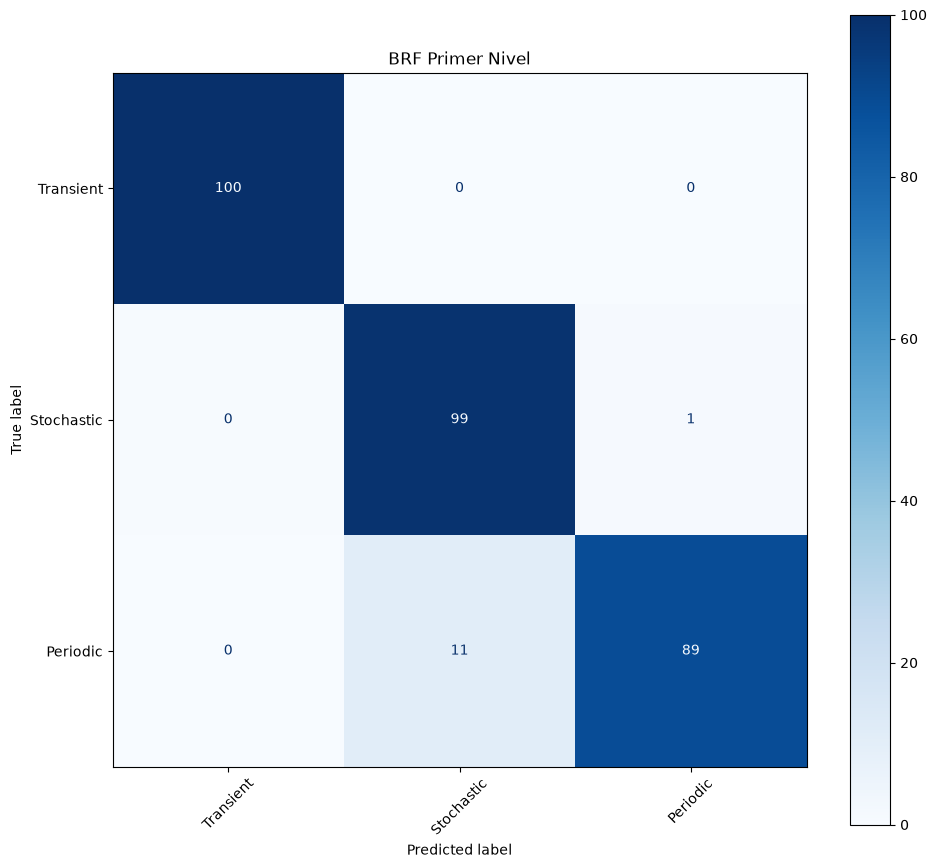

In [15]:
plot_confusionMatrix(y_true, y_pred, labels_classTop, "BRF Primer Nivel")

## BRF Segundo Nivel

### BRF Periodic

In [16]:
BRF2_periodic = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_periodic.fit(X_tr_Periodic, y_tr_Periodic)

y_true_periodic, y_pred_periodic = y_ts2, BRF2_periodic.predict(X_ts_Periodic)
y_pred_proba_periodic = BRF2_periodic.predict_proba(X_ts_Periodic)

#organizar por probabilidad
classes_order_proba_periodic = BRF2_periodic.classes_
print(classes_order_proba_periodic)

features_periodic = list(X_tr_Periodic)

['CEP' 'DSCT' 'E' 'LPV' 'Periodic-Other' 'RRL']


### BRF Stochastic

In [17]:
BRF2_stochastic = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_stochastic.fit(X_tr_Stochastic, y_tr_Stochastic)

y_true_stochastic, y_pred_stochastic = y_ts2, BRF2_stochastic.predict(X_ts_Stochastic)
y_pred_proba_stochastic = BRF2_stochastic.predict_proba(X_ts_Stochastic)

#organizar por probabilidad
classes_order_proba_stochastic = BRF2_stochastic.classes_
print(classes_order_proba_stochastic)

features_stochastic = list(X_tr_Stochastic)

['AGN' 'Blazar' 'CV/Nova' 'QSO' 'YSO']


### BRF Transient

In [18]:
BRF2_transient = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_transient.fit(X_tr_Transient, y_tr_Transient)

y_true_transient, y_pred_transient = y_ts2, BRF2_transient.predict(X_ts_Transient)
y_pred_proba_transient = BRF2_transient.predict_proba(X_ts_Transient)

#organizar por probabilidad
classes_order_proba_transient = BRF2_transient.classes_
print(classes_order_proba_transient)

features_transient = list(X_tr_Transient)

['SLSN' 'SNII' 'SNIa' 'SNIbc']


In [19]:
# generar probabilidades finales

#multiplicar la probabilidad del primer nivel por la del segundo
prob_periodic = y_pred_proba_periodic*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Periodic')[0][0]].T[:, np.newaxis]
prob_stochastic = y_pred_proba_stochastic*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Stochastic')[0][0]].T[:, np.newaxis]
prob_trainsient = y_pred_proba_transient*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Transient')[0][0]].T[:, np.newaxis]

#matriz final de probabilidades
#una columna para cada subclase, una fila para cada instancia
prob_final = np.concatenate((prob_stochastic,prob_trainsient,prob_periodic),axis=1)
print(f"Tamaño de Matriz de probabilidades: ", prob_final.shape)

#veificar funcionamiento adecuado. Suma las filas, la suma debe ser 1
print(f"Suma de columnas: {np.sum(prob_final,axis=1)}", f"Promedio: {np.mean(np.sum(prob_final,axis=1))}", f"Desviación Estándar: {np.std(np.sum(prob_final,axis=1))}")

#organizar los nombres de las clases igual que en prob_final
prob_final_class_names = np.concatenate((classes_order_proba_stochastic,classes_order_proba_transient,classes_order_proba_periodic))
print(prob_final_class_names)

#extrae la probabilidad mayor en cada fila y el nombre de la lase a la que corresponde
class_final_proba = np.amax(prob_final,axis=1)
class_final_index = np.argmax(prob_final,axis=1)
class_final_name = [prob_final_class_names[x] for x in class_final_index]

Tamaño de Matriz de probabilidades:  (20661, 15)
Suma de columnas: [1. 1. 1. ... 1. 1. 1.] Promedio: 1.0 Desviación Estándar: 8.865635521774088e-17
['AGN' 'Blazar' 'CV/Nova' 'QSO' 'YSO' 'SLSN' 'SNII' 'SNIa' 'SNIbc' 'CEP'
 'DSCT' 'E' 'LPV' 'Periodic-Other' 'RRL']


## Matriz de Confusión

| Classifier | Precision | Recall | F1-score |
| :--- | :--- | :--- | :--- |
| BRF—top | $0.96 \pm 0.01$ | $0.99 \pm 0.01$ | $0.97 \pm 0.01$ |
| BRF—bottom | $0.57 \pm 0.01$ | $0.76 \pm 0.02$ | $0.59 \pm 0.01$ |

                precision    recall  f1-score   support

           AGN       0.99      0.36      0.53       734
        Blazar       0.38      0.69      0.49       235
           CEP       0.60      0.03      0.07        87
       CV/Nova       0.18      0.81      0.29       161
          DSCT       0.59      0.66      0.62       119
             E       0.96      0.64      0.77      6543
           LPV       0.99      0.82      0.90      2165
Periodic-Other       0.11      0.41      0.17       195
           QSO       0.85      0.95      0.90      3915
           RRL       0.88      0.87      0.87      5869
          SLSN       0.25      0.80      0.38         5
          SNII       0.72      0.44      0.54        64
          SNIa       0.85      0.77      0.81       235
         SNIbc       0.14      0.67      0.23        18
           YSO       0.18      0.94      0.30       316

      accuracy                           0.78     20661
     macro avg       0.58      0.66      0.52 

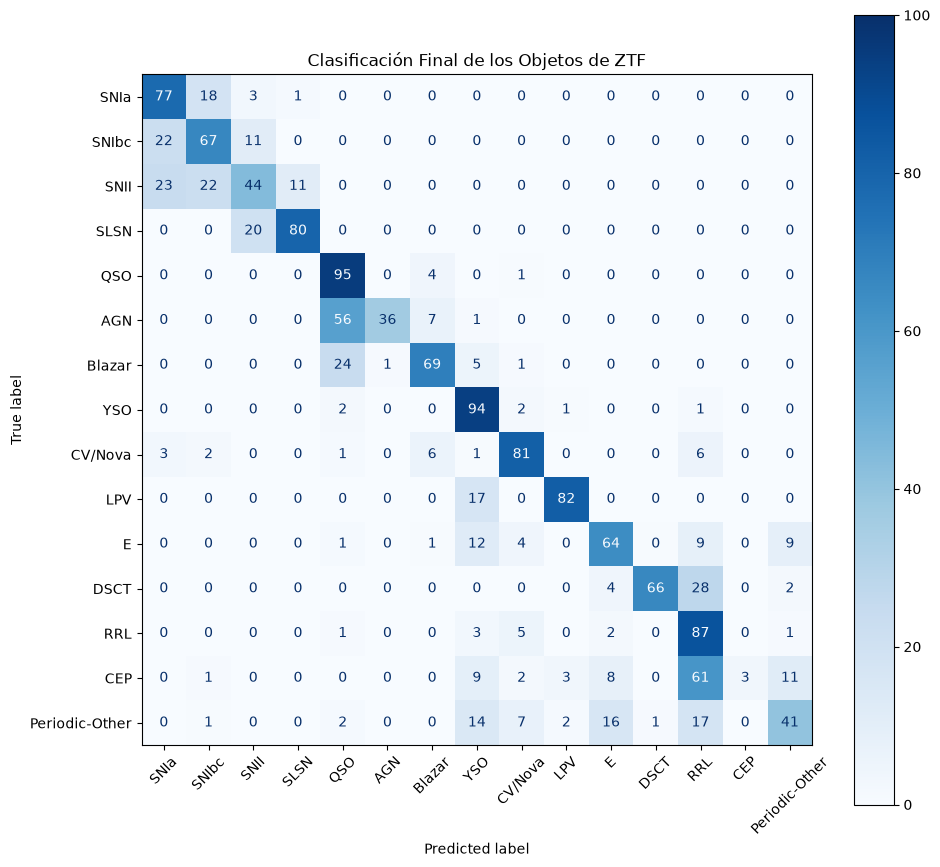

In [20]:
plot_confusionMatrix(y_ts2, class_final_name, labels_classALeRCE, "Clasificación Final de los Objetos de ZTF")

A pesar de haberle agregado sesgo al modelo entrenándolo con las fuentes más brillantes y probándolo con las tenues el resultado continúa siendo satisfactorio. La única clase que no es distinguida correctamente son las cefeidas que son confundidas con RR Lyrae, pero esto probablemente se deba más a la poca disponibilidad de datos que a una influencia recalcable de la magnitud.

El balanced accuracy redujo de 0.78 a 0.66 respecto al modelo usado en el artículo.

# Gboost con tratamiento de desbalance

Los autores también estudian el funcionamiento del algoritmo Gboost para la clasificación de las curvas de luz del ZTF. Sin embargo no ahondan en él debido a que este método no cuenta con un tratamiento nativo de desbalance de clases (necesario para este caso), pero resaltan que en un futuro estudio, implementando dicho tratamiento, se podrían conseguir buenos resultados.

En este caso se empleará el método de sobremuestreo SMOTE, que hace parte de la libreria imblearn de donde también proviene el método BRF

In [21]:
X = df_labeled.iloc[:, 1:153]
y_1, y_2 = df_labeled['classTop'], df_labeled['classALeRCE']

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_ts, y_train1, y_ts1, y_train2, y_ts2 = train_test_split(X, y_1, y_2,
                                                test_size=0.20,
                                                stratify=y_2,
                                                random_state=40)

El sobemuestreo solo se debe realizar sobre los datos de entrenamiento

In [23]:
from imblearn.over_sampling import SMOTE

#iniciar el SMOTE
smote = SMOTE(
    sampling_strategy='auto',       #define las proporciones del sobremuestreo, en este caso iguala las clases minoritarias con las mayoritarias
    random_state=40,                
    k_neighbors=5                   #cuantos vecinos cercanos usa para el sobremuestreo
)

In [24]:
#aplicar el smote al conjunto de entrenamiento
X_tr, y_tr2 = smote.fit_resample(
    X_train, y_train2
)

In [25]:
mapa = {
    'SNIa':'Transient', 'SNIbc':'Transient', 'SNII':'Transient', 'SLSN':'Transient',
    'CV/Nova':'Stochastic', 'Blazar':'Stochastic', 'QSO':'Stochastic', 'AGN':'Stochastic', 'YSO':'Stochastic',
    'LPV':'Periodic', 'CEP':'Periodic', 'RRL':'Periodic', 'DSCT':'Periodic', 'E':'Periodic', 'Periodic-Other':'Periodic'
}

# Agregar la columna con las 3 clases

y_tr1 = y_tr2.map(mapa)

In [26]:
X_tr_Stochastic = X_tr.loc[y_tr1 == 'Stochastic', :]
y_tr_Stochastic = y_tr2.loc[y_tr1 == 'Stochastic']

X_tr_Periodic = X_tr.loc[y_tr1 == 'Periodic', :]
y_tr_Periodic = y_tr2.loc[y_tr1 == 'Periodic']

X_tr_Transient = X_tr.loc[y_tr1 == 'Transient', :]
y_tr_Transient = y_tr2.loc[y_tr1 == 'Transient']

X_ts_Stochastic = X_ts
X_ts_Periodic = X_ts
X_ts_Transient = X_ts

print(f'Stochastic sub-classes: {y_tr_Stochastic.unique()} \n')
print(f'Periodic sub-classes: {y_tr_Periodic.unique()} \n')
print(f'Transient sub-classes: {y_tr_Transient.unique()} \n')

Stochastic sub-classes: <ArrowStringArray>
['AGN', 'QSO', 'YSO', 'Blazar', 'CV/Nova']
Length: 5, dtype: str 

Periodic sub-classes: <ArrowStringArray>
['RRL', 'E', 'LPV', 'CEP', 'DSCT', 'Periodic-Other']
Length: 6, dtype: str 

Transient sub-classes: <ArrowStringArray>
['SNIa', 'SNII', 'SNIbc', 'SLSN']
Length: 4, dtype: str 



## Comparación de distribución de clases

<Figure size 1000x600 with 0 Axes>

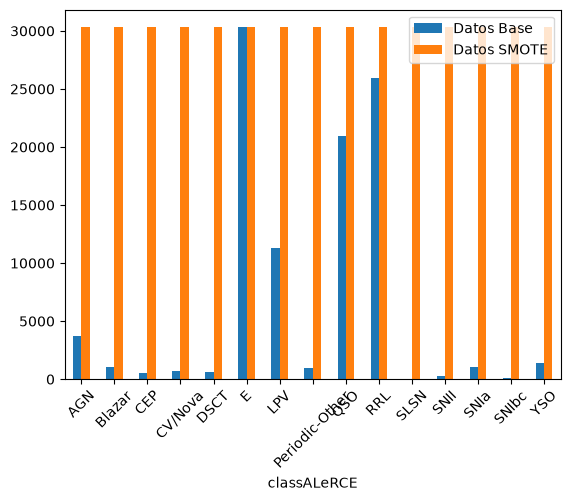

In [27]:
count_smote_2 = pd.DataFrame({'Datos Base': y_train2.value_counts(), 'Datos SMOTE': y_tr2.value_counts()})

plt.figure(figsize=(10,6))
count_smote_2.plot(kind='bar')
plt.xticks(rotation=45)
plt.show()

Se puede observar que la cantidad de datos de cada clase se ha igualado a las de Eclipsing Binary.

Con las clases equilibradas se puede aplicar GBoost sin miedo a sesgos

## GBoost de Dos Niveles

Para comparar adecuadamente, GBoost también se realiza en 2 niveles

## BRF Primer Nivel

In [28]:
from sklearn.ensemble import HistGradientBoostingClassifier

#Los hiperparámetros no se especifican en el artículo
GBB1 = HistGradientBoostingClassifier(random_state=40, 
                        max_iter=100, 
                        max_depth=None)

GBB1.fit(X_tr, y_tr1)

y_true, y_pred = y_ts1, GBB1.predict(X_ts)
y_pred_proba_GBB1 = GBB1.predict_proba(X_ts)

#organizar por probabilidad
classes_order_proba_GBB1 = GBB1.classes_
print(classes_order_proba_GBB1)

features = list(X_tr)

['Periodic' 'Stochastic' 'Transient']


### Matriz de Confusión

| Classifier | Precision | Recall | F1-score |
| :--- | :--- | :--- | :--- |
| GBoost—top | $0.99$ | $0.99$ | $0.99$ |
| GBoost—bottom | $0.72$ | $0.72$ | $0.71$ |

              precision    recall  f1-score   support

    Periodic       1.00      1.00      1.00     17414
  Stochastic       0.99      0.99      0.99      6942
   Transient       0.99      1.00      0.99       344

    accuracy                           0.99     24700
   macro avg       0.99      1.00      0.99     24700
weighted avg       0.99      0.99      0.99     24700

Accuracy: 0.99
Balanced accuracy: 1.00
macro precision:  0.99
macro recall:  1.00
macro F1:  0.99


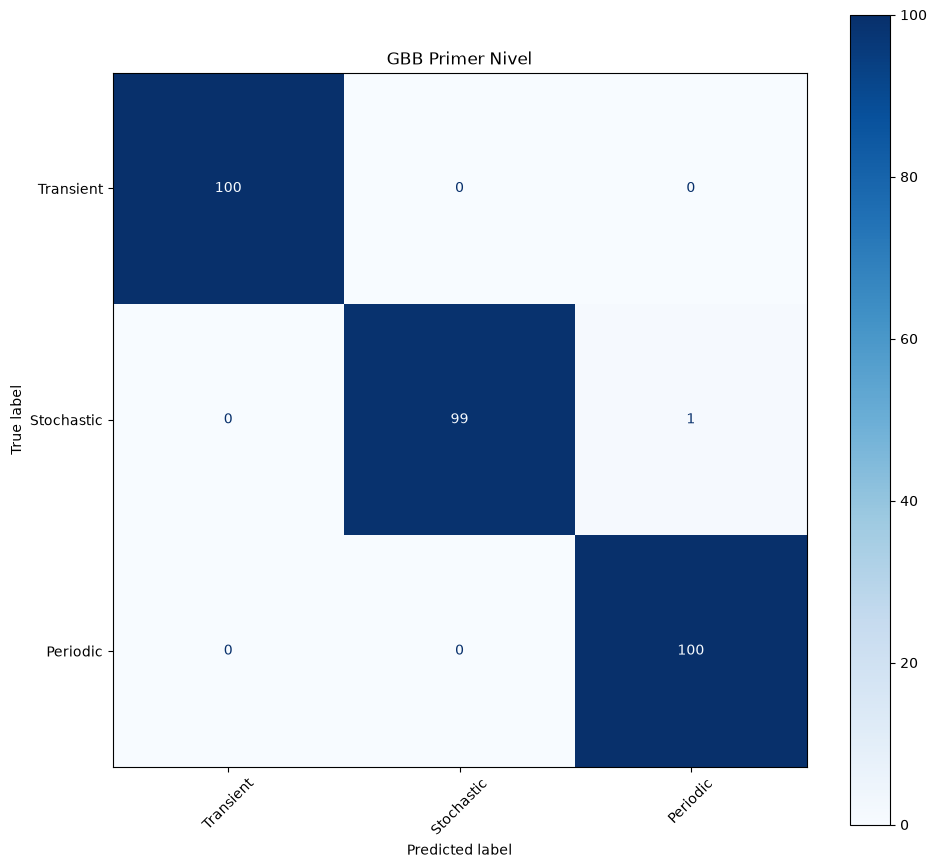

In [29]:
plot_confusionMatrix(y_true, y_pred, labels_classTop, "GBB Primer Nivel")

## BRF Segundo Nivel

### BRF Periodic

In [30]:
GBB2_periodic = HistGradientBoostingClassifier(random_state=40, 
                        max_iter=100, 
                        max_depth=5)

GBB2_periodic.fit(X_tr_Periodic, y_tr_Periodic)

y_true_periodic, y_pred_periodic = y_ts2, GBB2_periodic.predict(X_ts_Periodic)
y_pred_proba_periodic = GBB2_periodic.predict_proba(X_ts_Periodic)

#organizar por probabilidad
classes_order_proba_periodic = GBB2_periodic.classes_
print(classes_order_proba_periodic)

features_periodic = list(X_tr_Periodic)

['CEP' 'DSCT' 'E' 'LPV' 'Periodic-Other' 'RRL']


### BRF Stochastic

In [31]:
GBB2_stochastic = HistGradientBoostingClassifier(random_state=40, 
                        max_iter=100, 
                        max_depth=5)

GBB2_stochastic.fit(X_tr_Stochastic, y_tr_Stochastic)

y_true_stochastic, y_pred_stochastic = y_ts2, GBB2_stochastic.predict(X_ts_Stochastic)
y_pred_proba_stochastic = GBB2_stochastic.predict_proba(X_ts_Stochastic)

#organizar por probabilidad
classes_order_proba_stochastic = GBB2_stochastic.classes_
print(classes_order_proba_stochastic)

features_stochastic = list(X_tr_Stochastic)

['AGN' 'Blazar' 'CV/Nova' 'QSO' 'YSO']


### BRF Transient

In [32]:
GBB2_transient = HistGradientBoostingClassifier(random_state=40, 
                        max_iter=100, 
                        max_depth=5)

GBB2_transient.fit(X_tr_Transient, y_tr_Transient)

y_true_transient, y_pred_transient = y_ts2, GBB2_transient.predict(X_ts_Transient)
y_pred_proba_transient = GBB2_transient.predict_proba(X_ts_Transient)

#organizar por probabilidad
classes_order_proba_transient = GBB2_transient.classes_
print(classes_order_proba_transient)

features_transient = list(X_tr_Transient)

['SLSN' 'SNII' 'SNIa' 'SNIbc']


In [33]:
# generar probabilidades finales

#multiplicar la probabilidad del primer nivel por la del segundo
prob_periodic = y_pred_proba_periodic*y_pred_proba_GBB1[:,np.where(classes_order_proba_GBB1=='Periodic')[0][0]].T[:, np.newaxis]
prob_stochastic = y_pred_proba_stochastic*y_pred_proba_GBB1[:,np.where(classes_order_proba_GBB1=='Stochastic')[0][0]].T[:, np.newaxis]
prob_trainsient = y_pred_proba_transient*y_pred_proba_GBB1[:,np.where(classes_order_proba_GBB1=='Transient')[0][0]].T[:, np.newaxis]

#matriz final de probabilidades
#una columna para cada subclase, una fila para cada instancia
prob_final = np.concatenate((prob_stochastic,prob_trainsient,prob_periodic),axis=1)
print(f"Tamaño de Matriz de probabilidades: ", prob_final.shape)

#veificar funcionamiento adecuado. Suma las filas, la suma debe ser 1
print(f"Suma de columnas: {np.sum(prob_final,axis=1)}", f"Promedio: {np.mean(np.sum(prob_final,axis=1))}", f"Desviación Estándar: {np.std(np.sum(prob_final,axis=1))}")

#organizar los nombres de las clases igual que en prob_final
prob_final_class_names = np.concatenate((classes_order_proba_stochastic,classes_order_proba_transient,classes_order_proba_periodic))
print(prob_final_class_names)

#extrae la probabilidad mayor en cada fila y el nombre de la lase a la que corresponde
class_final_proba = np.amax(prob_final,axis=1)
class_final_index = np.argmax(prob_final,axis=1)
class_final_name = [prob_final_class_names[x] for x in class_final_index]

Tamaño de Matriz de probabilidades:  (24700, 15)
Suma de columnas: [1. 1. 1. ... 1. 1. 1.] Promedio: 1.0 Desviación Estándar: 1.6652895880305366e-16
['AGN' 'Blazar' 'CV/Nova' 'QSO' 'YSO' 'SLSN' 'SNII' 'SNIa' 'SNIbc' 'CEP'
 'DSCT' 'E' 'LPV' 'Periodic-Other' 'RRL']


## Matriz de Confusión

| Classifier | Precision | Recall | F1-score |
| :--- | :--- | :--- | :--- |
| GBoost—top | $0.99$ | $0.99$ | $0.99$ |
| GBoost—bottom | $0.72$ | $0.72$ | $0.71$ |
| BRF—bottom (two levels) | $0.57$ | $0.76$ | $0.59$ |

                precision    recall  f1-score   support

           AGN       0.74      0.79      0.76       933
        Blazar       0.69      0.62      0.66       253
           CEP       0.60      0.69      0.64       124
       CV/Nova       0.87      0.81      0.84       174
          DSCT       0.67      0.74      0.70       146
             E       0.95      0.95      0.95      7581
           LPV       0.99      0.99      0.99      2815
Periodic-Other       0.42      0.43      0.43       251
           QSO       0.95      0.95      0.95      5234
           RRL       0.96      0.95      0.96      6497
          SLSN       1.00      0.60      0.75         5
          SNII       0.81      0.73      0.77        66
          SNIa       0.90      0.97      0.93       254
         SNIbc       0.42      0.26      0.32        19
           YSO       0.90      0.90      0.90       348

      accuracy                           0.94     24700
     macro avg       0.79      0.76      0.77 

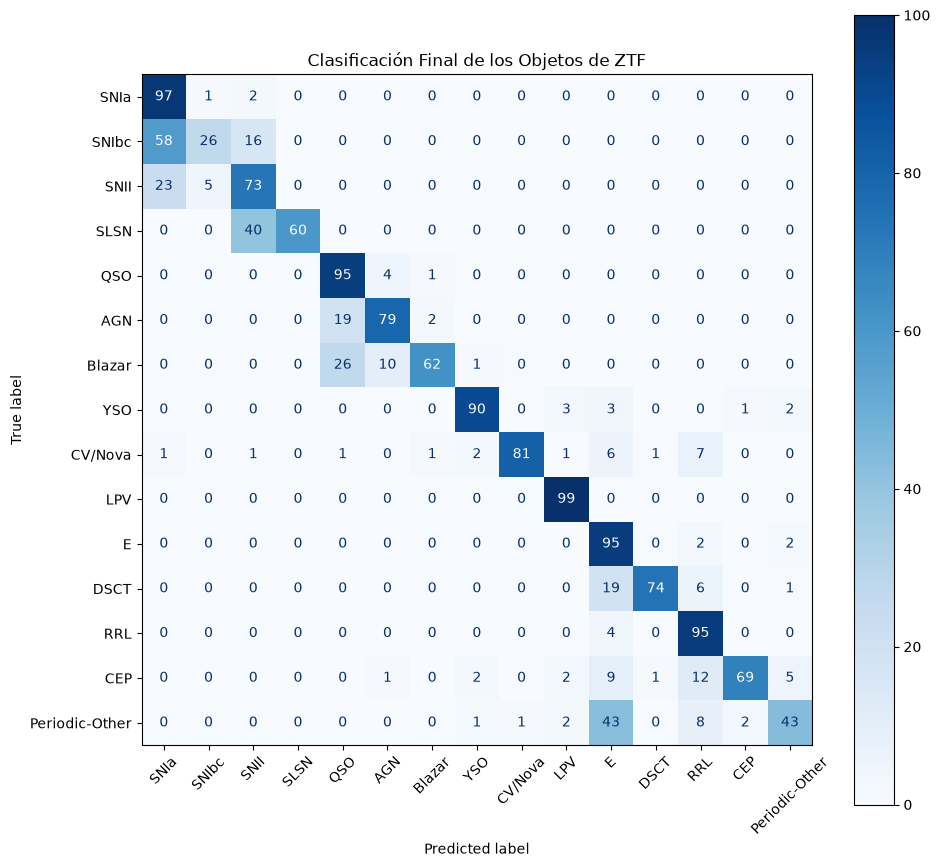

In [34]:
plot_confusionMatrix(y_ts2, class_final_name, labels_classALeRCE, "Clasificación Final de los Objetos de ZTF")